# CyberBERT V1.1 — Alineado con la guía de clasificación Hugging Face de ICESI
**Proyecto original:** clasificación de asociación documentada a ransomware en CISA KEV.
**Extensiones de la guía:** tokenización y máscaras, arquitectura y cabezas lineal/MLP congeladas opcionales, fine-tuning completo, EDA, línea base y métricas.


## 0. Dependencias (una sola celda)
En Colab selecciona **GPU T4**. Ejecuta una sola vez; si cambian bibliotecas ya cargadas, reinicia sesión Python y continúa con la siguiente celda, sin reinstalar. No se instala Ollama, Gradio ni LangChain.

In [ ]:
%pip -q install "transformers>=4.48,<5" "accelerate>=1,<2" "scikit-learn>=1.3,<2" "pandas>=2.1,<3" "matplotlib>=3.7" "requests>=2.31" "safetensors>=0.4"

## 1. Comprobación del entorno y reproducibilidad

In [ ]:
import os, re, json, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import requests, torch, transformers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, precision_score, recall_score, accuracy_score,
                             balanced_accuracy_score, average_precision_score, roc_auc_score,
                             precision_recall_curve, roc_curve)
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
OUT=Path('cyberbert_resultados'); OUT.mkdir(exist_ok=True)
print('Torch:',torch.__version__,'Transformers:',transformers.__version__)
print('GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU (entrenamiento mucho más lento)')

Torch: 2.11.0+cu130 Transformers: 4.57.6
GPU: Tesla T4


## 2. Datos públicos CISA KEV: adquisición y trazabilidad
Fuente oficial: https://github.com/cisagov/kev-data ; se guarda copia local del JSON y la fecha de descarga. No se suben datos internos de EMCALI.

In [ ]:
DATA_URL='https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json'
r=requests.get(DATA_URL,timeout=40); r.raise_for_status()
raw=r.json()
assert 'vulnerabilities' in raw, 'Formato CISA KEV inesperado'
with open(OUT/'cisa_kev_raw.json','w',encoding='utf-8') as f:json.dump(raw,f,ensure_ascii=False,indent=2)
df=pd.DataFrame(raw['vulnerabilities'])
print('Catálogo:',raw.get('catalogVersion'),'fecha:',raw.get('dateReleased'),'registros:',len(df))
print('Columnas:',df.columns.tolist())
display(df.head(3))

Catálogo: 2026.10.08 fecha: 2026-10-08T20:09:18.9833Z registros: 1739
Columnas: ['cveID', 'vendorProject', 'product', 'vulnerabilityName', 'dateAdded', 'shortDescription', 'requiredAction', 'dueDate', 'knownRansomwareCampaignUse', 'forensicTriage', 'notes', 'cwes']


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes
0,CVE-2015-5477,ISC,BIND,ISC BIND Data Processing Errors Vulnerability,2026-10-08,ISC BIND contains a data processing errors vul...,Apply mitigations in accordance with vendor in...,2026-10-11,Unknown,No,This vulnerability could affect an open-source...,[CWE-19]
1,CVE-2016-3081,Apache,Struts,Apache Struts Command Injection Vulnerability,2026-10-08,Apache Struts contains a command injection vul...,Apply mitigations in accordance with vendor in...,2026-10-11,Unknown,Yes,This vulnerability could affect an open-source...,[CWE-77]
2,CVE-2023-22894,Strapi,Strapi,Strapi Cleartext Storage of Sensitive Informat...,2026-10-08,Strapi contains a cleartext storage of sensiti...,Apply mitigations in accordance with vendor in...,2026-10-11,Unknown,Yes,This vulnerability could affect an open-source...,[CWE-312]


## 3. Preparación de etiquetas y textos
El modelo solo recibe `vulnerabilityName` + `shortDescription`. **No** recibe `knownRansomwareCampaignUse`, fechas, notas o acciones que puedan revelar la etiqueta. Conservamos `cveID` para trazabilidad, pero no lo incorporamos al texto de entrada.

In [ ]:
needed={'cveID','vulnerabilityName','shortDescription','knownRansomwareCampaignUse'}
assert needed.issubset(df.columns), f'Faltan columnas {needed-set(df.columns)}'
work=df.copy()
work['label_raw']=work['knownRansomwareCampaignUse'].astype(str).str.strip()
print('Etiquetas originales:');display(work['label_raw'].value_counts(dropna=False).to_frame('registros'))
work=work[work.label_raw.isin(['Known','Unknown'])].copy()
work['label']=(work.label_raw=='Known').astype(int)
work['text']=(work['vulnerabilityName'].fillna('').astype(str)+' . '+work['shortDescription'].fillna('').astype(str)).str.strip()
work=work.dropna(subset=['cveID']).drop_duplicates(subset=['cveID'])
work=work.loc[work['text'].str.len()>=30].reset_index(drop=True)
assert work['label'].nunique()==2,'Hay menos de 2 clases: no se puede entrenar un clasificador binario'
assert work['label'].value_counts().min()>=6,'Muy pocos registros en alguna clase para dividir'
print('Filas válidas:',len(work)); display(work[['cveID','text','label_raw']].head(4))

Etiquetas originales:


,registros
label_raw,
Unknown,1378
Known,361


Filas válidas: 1739


,cveID,text,label_raw
0,CVE-2015-5477,ISC BIND Data Processing Errors Vulnerability ...,Unknown
1,CVE-2016-3081,Apache Struts Command Injection Vulnerability ...,Unknown
2,CVE-2023-22894,Strapi Cleartext Storage of Sensitive Informat...,Unknown
3,CVE-2021-3199,ONLYOFFICE Docs Server Path Traversal Vulnerab...,Unknown


## 4. EDA: distribución de clases, proveedores, texto y tiempo
El EDA incluye diagnóstico de desequilibrio, longitud de descripciones y evolución temporal de registros (fecha de incorporación, no necesariamente fecha de explotación).

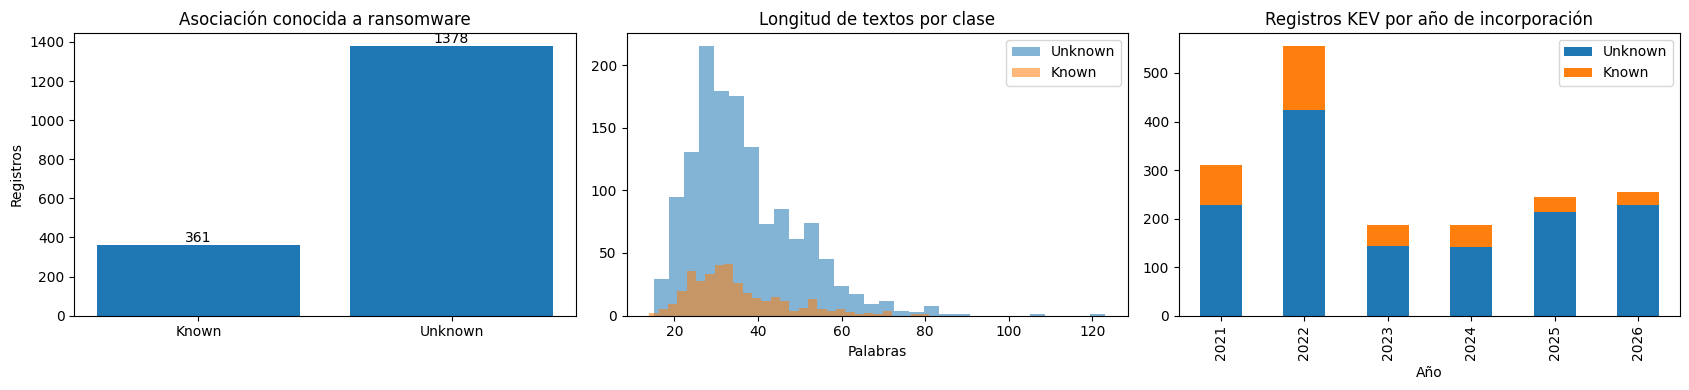

Tasa clase conocida: 0.2076
Longitud mediana (palabras): 33.0


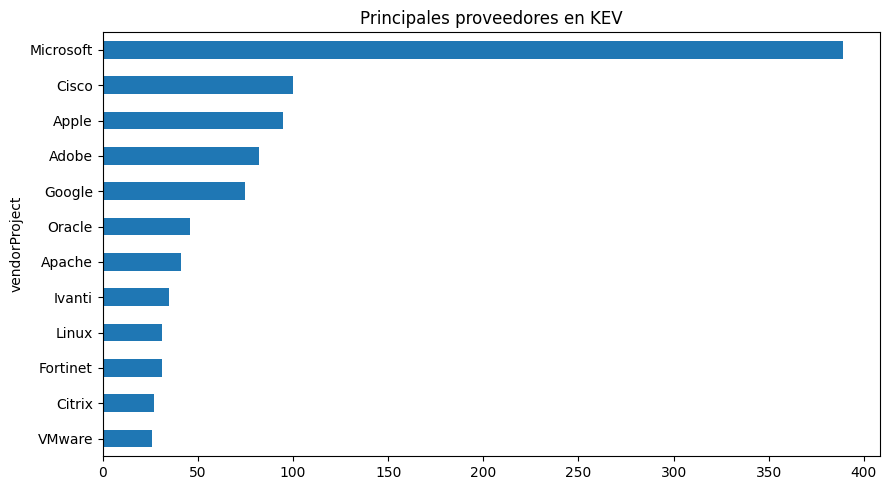

In [ ]:
work['n_palabras']=work.text.str.split().str.len()
work['dateAdded_dt']=pd.to_datetime(work.get('dateAdded'),errors='coerce')
fig,ax=plt.subplots(1,3,figsize=(17,4))
counts=work.label_raw.value_counts().reindex(['Known','Unknown']).fillna(0)
ax[0].bar(counts.index,counts.values); ax[0].set_title('Asociación conocida a ransomware');ax[0].set_ylabel('Registros')
for i,v in enumerate(counts.values):ax[0].text(i,v,str(int(v)),ha='center',va='bottom')
for x in [0,1]:
    ax[1].hist(work.loc[work.label==x,'n_palabras'],bins=30,alpha=.55,label='Known' if x else 'Unknown')
ax[1].legend();ax[1].set_title('Longitud de textos por clase');ax[1].set_xlabel('Palabras')
annual=work.groupby([work.dateAdded_dt.dt.year,'label']).size().unstack(fill_value=0)
annual.columns=['Unknown' if x==0 else 'Known' for x in annual.columns]
annual.plot(kind='bar',stacked=True,ax=ax[2]);ax[2].set_title('Registros KEV por año de incorporación');ax[2].set_xlabel('Año')
plt.tight_layout();plt.savefig(OUT/'eda_principal.png',dpi=160);plt.show()
print('Tasa clase conocida:',round(work.label.mean(),4))
print('Longitud mediana (palabras):',work.n_palabras.median())
if 'vendorProject' in work:
    vendors=work.vendorProject.fillna('No informado').value_counts().head(12)
    ax=vendors.sort_values().plot.barh(figsize=(9,5),title='Principales proveedores en KEV')
    plt.tight_layout();plt.savefig(OUT/'eda_proveedores.png',dpi=160);plt.show()

## 5. Separación reproducible y control de fuga
15 % prueba, aproximadamente 15 % validación, resto entrenamiento; estratificación por clase. El conjunto de prueba **no** se utiliza para seleccionar el umbral o ajustar hiperparámetros.

In [ ]:
trainval,test=train_test_split(work,test_size=.15,random_state=SEED,stratify=work.label)
train,val=train_test_split(trainval,test_size=.15/.85,random_state=SEED,stratify=trainval.label)
for name,split in [('train',train),('val',val),('test',test)]:
    print(name,len(split),'Known:',round(split.label.mean(),3));split[['cveID','label']].to_csv(OUT/f'{name}_ids.csv',index=False)
assert set(train.cveID).isdisjoint(val.cveID) and set(train.cveID).isdisjoint(test.cveID)

train 1217 Known: 0.208
val 261 Known: 0.207
test 261 Known: 0.207


## 6. Línea base: TF-IDF + regresión logística
Modelo interpretable para cuantificar si BERT aporta una mejora real. Se ajusta únicamente sobre entrenamiento; se conserva separación independiente de test.

In [ ]:
tfidf=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=30000,sublinear_tf=True)
X_train=tfidf.fit_transform(train.text);X_val=tfidf.transform(val.text);X_test=tfidf.transform(test.text)
logreg=LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED)
t0=time.perf_counter();logreg.fit(X_train,train.label);base_fit=time.perf_counter()-t0
p_base_val=logreg.predict_proba(X_val)[:,1]
p_base_test=logreg.predict_proba(X_test)[:,1]
print('TF-IDF vocab:',len(tfidf.vocabulary_),'ajuste:',round(base_fit,2),'s')

TF-IDF vocab: 4849 ajuste: 0.08 s


## 7. BERT base: fine-tuning supervisado en GPU
Se usa el encoder BERT `google-bert/bert-base-uncased` (textos CISA predominantemente en inglés). Para acortar la práctica, se limita entrenamiento a 2 épocas y hasta 1600 ejemplos; la evaluación se hace sobre los mismos conjuntos val/test completos. Esto debe consignarse como limitación experimental.

In [ ]:
MODEL_ID='google-bert/bert-base-uncased'
MAX_LEN=128
MAX_TRAIN=1600
train_bert=train.sample(frac=1,random_state=SEED)
if len(train_bert)>MAX_TRAIN:
    train_bert,_=train_test_split(train_bert,train_size=MAX_TRAIN,random_state=SEED,stratify=train_bert.label)
print('Entrenamiento BERT:',len(train_bert),'Validación:',len(val),'Test:',len(test))
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID)
class TextDataset(torch.utils.data.Dataset):
    def __init__(self,frame):
        self.enc=tokenizer(frame.text.tolist(),truncation=True,max_length=MAX_LEN)
        self.labels=frame.label.tolist()
    def __len__(self):return len(self.labels)
    def __getitem__(self,i):return {**{k:v[i] for k,v in self.enc.items()},'labels':int(self.labels[i])}
tr_ds=TextDataset(train_bert);va_ds=TextDataset(val);te_ds=TextDataset(test)
model=AutoModelForSequenceClassification.from_pretrained(MODEL_ID,num_labels=2,id2label={0:'Unknown',1:'Known'},label2id={'Unknown':0,'Known':1})
print('Modelo:',MODEL_ID,'GPU CUDA:',torch.cuda.is_available())

Entrenamiento BERT: 1217 Validación: 261 Test: 261


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Modelo: google-bert/bert-base-uncased GPU CUDA: True


## 7A. Tokenizador, vocabulario, *input_ids* y máscaras (guía ICESI)

La guía del profesor explora expresamente el tokenizador asociado al modelo, sus tokens, tamaño de vocabulario, longitud máxima y máscaras. En nuestro caso el texto CISA KEV está predominantemente en **inglés**, por ello utilizamos `bert-base-uncased` y su tokenizador correspondiente, y NO copiamos el BERT español del caso de noticias.

**Pregunta:** ¿qué proporción de las descripciones se truncaría con `MAX_LEN=128`? Esta evidencia justifica la configuración. La inspección de `tokens`, `input_ids` y `attention_mask` documenta cómo BERT representa los textos.

CVE: CVE-2017-9248
Primeros tokens: ['[CLS]', 'progress', 'tel', '##erik', 'ui', 'for', 'as', '##p', '.', 'net', 'ajax', 'and', 'site', '##fin', '##ity', 'crypt', '##ographic', 'weakness', 'vulnerability', '.', 'progress', 'tel', '##erik', 'ui', 'for']
Primeros input_ids: [101, 5082, 10093, 27350, 21318, 2005, 2004, 2361, 1012, 5658, 18176, 1998, 2609, 16294, 3012, 19888, 13705, 11251, 18130, 1012, 5082, 10093, 27350, 21318, 2005]
Primeros attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Vocabulario: 30522
Longitud máxima admitida por tokenizer: 512
Textos que exceden 128 tokens: 0.2%


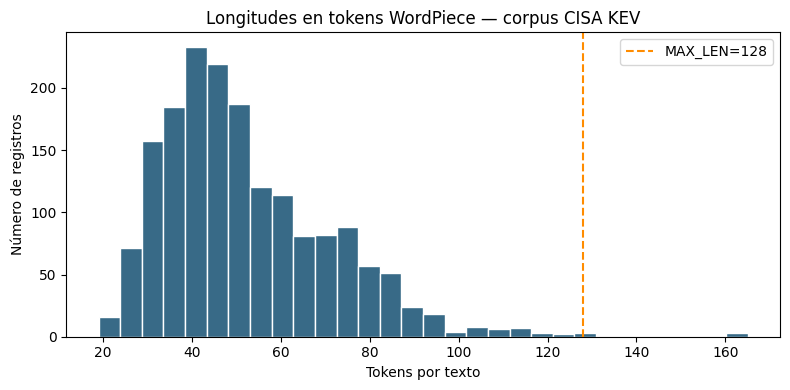

In [ ]:
ejemplo=train_bert.iloc[0]['text']
inspeccion=tokenizer(ejemplo, truncation=True, padding='max_length', max_length=MAX_LEN)
print('CVE:',train_bert.iloc[0]['cveID'])
print('Primeros tokens:',tokenizer.convert_ids_to_tokens(inspeccion['input_ids'][:25]))
print('Primeros input_ids:',inspeccion['input_ids'][:25])
print('Primeros attention_mask:',inspeccion['attention_mask'][:25])
print('Vocabulario:',tokenizer.vocab_size)
print('Longitud máxima admitida por tokenizer:',tokenizer.model_max_length)
longitudes=[len(tokenizer.encode(t,add_special_tokens=True,truncation=False)) for t in work.text.tolist()]
truncados=np.mean(np.asarray(longitudes)>MAX_LEN)
print(f'Textos que exceden {MAX_LEN} tokens: {truncados:.1%}')
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(longitudes,bins=30,color='#386a87',edgecolor='white')
ax.axvline(MAX_LEN,color='darkorange',ls='--',label=f'MAX_LEN={MAX_LEN}')
ax.set(title='Longitudes en tokens WordPiece — corpus CISA KEV',xlabel='Tokens por texto',ylabel='Número de registros')
ax.legend();plt.tight_layout();plt.savefig(OUT/'distribucion_tokens_bert.png',dpi=150);plt.show()


## 7B. Arquitectura BERT y transferencia de aprendizaje (guía ICESI)

La guía compara **cabeza lineal congelando BERT**, **cabeza MLP congelando BERT** y **fine-tuning completo**. Reproducimos ese protocolo como experimento adicional, sin utilizar el conjunto de prueba para elegir configuraciones. Para reducir el costo en Colab, este bloque es **opcional**; cambia `EJECUTAR_CABEZAS=True` para ejecutar una época por cabeza sobre hasta 600 muestras. El fine-tuning principal se realiza más adelante.

Una arquitectura más compleja NO garantiza mejora: podría sobreajustar una clase poco frecuente. Las comparaciones de cabezas se hacen en **validación**; el test permanece reservado.

In [ ]:
print('Arquitectura de la cabeza estándar:',model.classifier)
print('Dimensión de la salida BERT:',model.config.hidden_size)
print('Parámetros totales:',sum(p.numel() for p in model.parameters()))
print('Entrenables antes de congelar:',sum(p.numel() for p in model.parameters() if p.requires_grad))
# Inspección forward con batch real, sin conservar gradientes
muestra=tokenizer(ejemplo,return_tensors='pt',truncation=True,max_length=MAX_LEN)
model.eval()
with torch.inference_mode():
    logits=model(**muestra).logits
print('Logits del clasificador, forma:',tuple(logits.shape))
print('Probabilidades de ejemplo (modelo NO entrenado aún):',torch.softmax(logits,dim=-1).tolist())


Arquitectura de la cabeza estándar: Linear(in_features=768, out_features=2, bias=True)
Dimensión de la salida BERT: 768
Parámetros totales: 109483778
Entrenables antes de congelar: 109483778
Logits del clasificador, forma: (1, 2)
Probabilidades de ejemplo (modelo NO entrenado aún): [[0.4450515806674957, 0.5549483895301819]]


In [ ]:
EJECUTAR_CABEZAS= True   # Activar para comparar transferencia congelada: ~2 entrenamientos breves.
comparacion_cabezas=[]
if EJECUTAR_CABEZAS:
    import torch.nn as nn
    import inspect
    from copy import deepcopy
    # Mantener exactamente la misma partición de entrenamiento/validación.
    muestra_cabezas=train_bert.sample(n=min(600,len(train_bert)),random_state=SEED)
    ds_cabezas=TextDataset(muestra_cabezas)
    for nombre,cabeza_tipo in [('Lineal_congelada','lineal'),('MLP_congelada','mlp')]:
        m=AutoModelForSequenceClassification.from_pretrained(MODEL_ID,num_labels=2)
        for p in m.base_model.parameters():p.requires_grad=False
        if cabeza_tipo=='mlp':
            d=m.config.hidden_size
            m.classifier=nn.Sequential(nn.Linear(d,128),nn.ReLU(),nn.Dropout(.2),nn.Linear(128,2))
        print(nombre,'parámetros entrenables:',sum(p.numel() for p in m.parameters() if p.requires_grad))
        k={'output_dir':str(OUT/nombre),'num_train_epochs':1,'per_device_train_batch_size':8,
           'per_device_eval_batch_size':16,'learning_rate':5e-4,'report_to':'none','save_strategy':'no',
           'seed':SEED,'fp16':torch.cuda.is_available()}
        par=inspect.signature(TrainingArguments.__init__).parameters
        k['eval_strategy' if 'eval_strategy' in par else 'evaluation_strategy']='epoch'
        a=TrainingArguments(**k)
        tr=Trainer(model=m,args=a,train_dataset=ds_cabezas,eval_dataset=va_ds,
                   data_collator=DataCollatorWithPadding(tokenizer=tokenizer),compute_metrics=compute_metrics if 'compute_metrics' in globals() else None)
        tic=time.perf_counter();tr.train();t=time.perf_counter()-tic
        pred=tr.predict(va_ds).predictions.argmax(axis=1)
        comparacion_cabezas.append({'modelo':nombre,'F1_macro_validacion':f1_score(val.label,pred,average='macro',zero_division=0),'segundos':t})
        del tr,m;import gc;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    display(pd.DataFrame(comparacion_cabezas))
    pd.DataFrame(comparacion_cabezas).to_csv(OUT/'cabezas_congeladas_validacion.csv',index=False)
else:
    print('Comparación de cabezas congeladas omitida. Cambia EJECUTAR_CABEZAS=True para ejecutarla.')


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Lineal_congelada parámetros entrenables: 1538


Epoch,Training Loss,Validation Loss
1,No log,0.525333


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


MLP_congelada parámetros entrenables: 98690


Epoch,Training Loss,Validation Loss
1,No log,0.521964


,modelo,F1_macro_validacion,segundos
0,Lineal_congelada,0.442308,7.882876
1,MLP_congelada,0.442308,6.143922


### Interpretación del experimento adicional

Tras ejecutar, compara F1 macro en validación, parámetros entrenables y latencia de entrenamiento. Si la MLP no supera la capa lineal, explica el costo adicional y posible sobreajuste. El modelo final con todas las capas descongeladas se entrena en las siguientes secciones del cuaderno. **No reportes las métricas del notebook guía de noticias como resultados de CyberBERT.**

## 8. Entrenamiento y curva de pérdida
Aviso: el entrenamiento de una BERT base con GPU T4 puede durar varios minutos. La cabeza de clasificación se inicializa aleatoriamente, lo cual es esperado.

Epoch,Training Loss,Validation Loss,F1 Macro,F1 Known
1,0.472000,0.525484,0.442308,0.000000
2,0.470400,0.455607,0.493612,0.101695


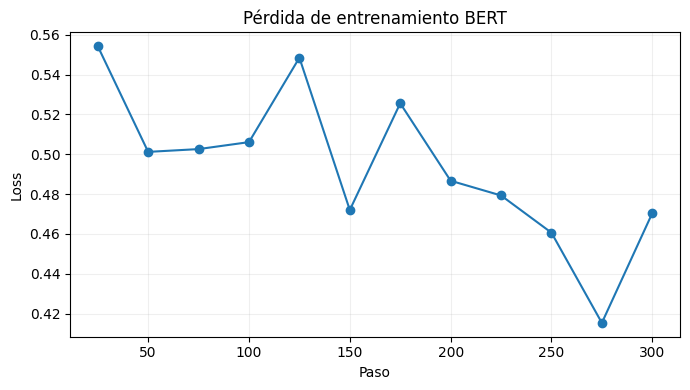

Entrenamiento BERT (s): 40.36


In [ ]:
import inspect
args_kwargs=dict(output_dir=str(OUT/'bert_checkpoint'),num_train_epochs=2,per_device_train_batch_size=8,
                 per_device_eval_batch_size=16,learning_rate=2e-5,weight_decay=.01,
                 logging_steps=25,save_strategy='no',report_to='none',seed=SEED,fp16=torch.cuda.is_available())
param=inspect.signature(TrainingArguments.__init__).parameters
if 'eval_strategy' in param:args_kwargs['eval_strategy']='epoch'
else:args_kwargs['evaluation_strategy']='epoch'
args=TrainingArguments(**args_kwargs)
def compute_metrics(e):
    pred=np.argmax(e.predictions,axis=-1)
    return {'f1_macro':f1_score(e.label_ids,pred,average='macro',zero_division=0),
            'f1_known':f1_score(e.label_ids,pred,pos_label=1,zero_division=0)}
trainer=Trainer(model=model,args=args,train_dataset=tr_ds,eval_dataset=va_ds,
                data_collator=DataCollatorWithPadding(tokenizer=tokenizer),compute_metrics=compute_metrics)
t0=time.perf_counter();trainer.train();bert_fit=time.perf_counter()-t0
logs=pd.DataFrame(trainer.state.log_history)
if 'loss' in logs:
    plt.figure(figsize=(7,4));plt.plot(logs.dropna(subset=['loss']).step,logs.dropna(subset=['loss']).loss,marker='o');plt.title('Pérdida de entrenamiento BERT');plt.xlabel('Paso');plt.ylabel('Loss');plt.grid(alpha=.2);plt.tight_layout();plt.savefig(OUT/'bert_loss.png',dpi=160);plt.show()
print('Entrenamiento BERT (s):',round(bert_fit,2))

## 9. Probabilidades y ajuste de umbral en validación
Se elige el umbral que maximiza F1 de la clase `Known` en **validación**. Ese mismo umbral se aplica a prueba sin revisarlo.

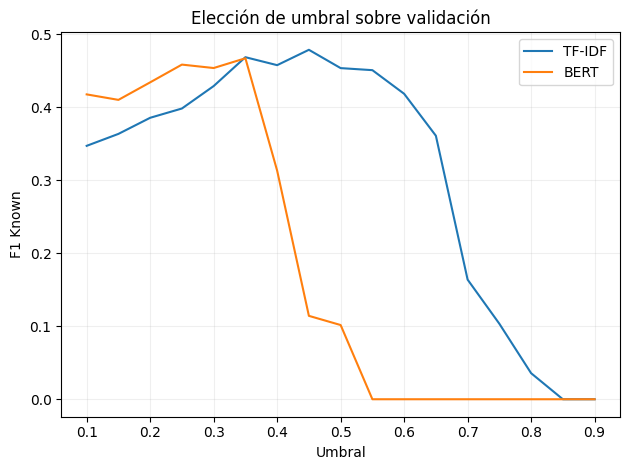

Umbrales fijados: TF-IDF 0.45000000000000007 BERT 0.3500000000000001


In [ ]:
from scipy.special import softmax
p_bert_val=softmax(trainer.predict(va_ds).predictions,axis=1)[:,1]
p_bert_test=softmax(trainer.predict(te_ds).predictions,axis=1)[:,1]
def select_threshold(y,p):
    options=np.arange(.10,.91,.05)
    scores=[f1_score(y,np.asarray(p)>=t,zero_division=0) for t in options]
    return float(options[int(np.argmax(scores))]),pd.DataFrame({'umbral':options,'F1_val':scores})
t_base,curve_base=select_threshold(val.label,p_base_val)
t_bert,curve_bert=select_threshold(val.label,p_bert_val)
plt.plot(curve_base.umbral,curve_base.F1_val,label='TF-IDF');plt.plot(curve_bert.umbral,curve_bert.F1_val,label='BERT');plt.legend();plt.title('Elección de umbral sobre validación');plt.xlabel('Umbral');plt.ylabel('F1 Known');plt.grid(alpha=.2);plt.tight_layout();plt.savefig(OUT/'umbrales_validacion.png',dpi=160);plt.show()
print('Umbrales fijados: TF-IDF',t_base,'BERT',t_bert)

## 10. Evaluación FINAL sobre prueba independiente
Reportar Macro-F1, F1 Known, precisión, recall, PR-AUC, ROC-AUC, balanced accuracy, matriz de confusión y tiempo de entrenamiento. No confundir **clasificar metadatos** con demostrar explotación real.

 |  TF-IDF + LogReg  |                precision    recall  f1-score   support

     Unknown       0.92      0.75      0.83       207
       Known       0.44      0.74      0.55        54

    accuracy                           0.75       261
   macro avg       0.68      0.75      0.69       261
weighted avg       0.82      0.75      0.77       261

 |  BERT fine-tuned  |                precision    recall  f1-score   support

     Unknown       0.89      0.87      0.88       207
       Known       0.54      0.59      0.57        54

    accuracy                           0.81       261
   macro avg       0.72      0.73      0.72       261
weighted avg       0.82      0.81      0.82       261



,0,1
modelo,TF-IDF + LogReg,BERT fine-tuned
umbral,0.45,0.35
accuracy,0.750958,0.812261
balanced_accuracy,0.747182,0.731079
precision_known,0.43956,0.542373
recall_known,0.740741,0.592593
f1_known,0.551724,0.566372
f1_macro,0.689655,0.723284
pr_auc,0.57723,0.536206
roc_auc,0.839596,0.82385


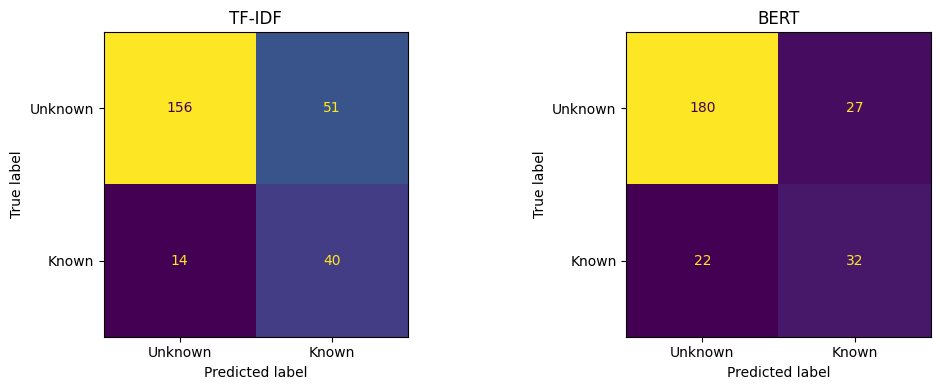

In [ ]:
def eval_model(name,y,p,threshold,fit_time):
    pred=(np.asarray(p)>=threshold).astype(int)
    metrics={'modelo':name,'umbral':threshold,'accuracy':accuracy_score(y,pred),
             'balanced_accuracy':balanced_accuracy_score(y,pred),
             'precision_known':precision_score(y,pred,zero_division=0),
             'recall_known':recall_score(y,pred,zero_division=0),
             'f1_known':f1_score(y,pred,zero_division=0),
             'f1_macro':f1_score(y,pred,average='macro',zero_division=0),
             'pr_auc':average_precision_score(y,p),
             'roc_auc':roc_auc_score(y,p) if len(set(y))==2 else np.nan,
             'train_seconds':fit_time}
    print(' | ',name,' | ',classification_report(y,pred,target_names=['Unknown','Known'],zero_division=0))
    return metrics,pred
m_base,pred_base=eval_model('TF-IDF + LogReg',test.label,p_base_test,t_base,base_fit)
m_bert,pred_bert=eval_model('BERT fine-tuned',test.label,p_bert_test,t_bert,bert_fit)
results=pd.DataFrame([m_base,m_bert]);display(results.T)
results.to_csv(OUT/'metricas_test.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,pred,name in zip(axs,[pred_base,pred_bert],['TF-IDF','BERT']):
    ConfusionMatrixDisplay(confusion_matrix(test.label,pred),display_labels=['Unknown','Known']).plot(ax=ax,colorbar=False)
    ax.set_title(name)
plt.tight_layout();plt.savefig(OUT/'matrices_confusion.png',dpi=160);plt.show()

## 11. Curvas PR / ROC y análisis comparativo
PR-AUC es especialmente útil cuando la clase Known es minoritaria. Interpretar ROC-AUC y F1 junto a la distribución de clases.

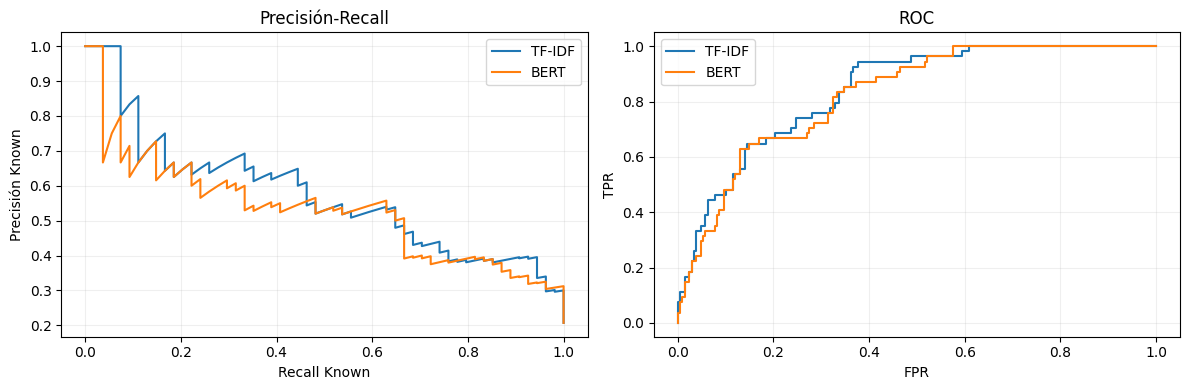

Δ F1 macro BERT - baseline: 0.0336


In [ ]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
for name,p in [('TF-IDF',p_base_test),('BERT',p_bert_test)]:
    prec,rec,_=precision_recall_curve(test.label,p)
    fpr,tpr,_=roc_curve(test.label,p)
    axs[0].plot(rec,prec,label=name);axs[1].plot(fpr,tpr,label=name)
axs[0].set(title='Precisión-Recall',xlabel='Recall Known',ylabel='Precisión Known')
axs[1].set(title='ROC',xlabel='FPR',ylabel='TPR')
for ax in axs:ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUT/'curvas_pr_roc.png',dpi=160);plt.show()
print('Δ F1 macro BERT - baseline:',round(m_bert['f1_macro']-m_base['f1_macro'],4))

## 12. Errores y trazabilidad de predicciones
Inspección cualitativa para analizar errores por fabricante, ambigüedad de lenguaje, y límites del corpus. **No elegir ejemplos en función del resultado deseado**.

In [ ]:
audit=test[['cveID','vendorProject','vulnerabilityName','shortDescription','label']].copy()
audit['pred_bert']=pred_bert;audit['prob_known_bert']=p_bert_test
audit['pred_tfidf']=pred_base;audit['prob_known_tfidf']=p_base_test
audit['error_bert']=audit.label!=audit.pred_bert
audit.to_csv(OUT/'predicciones_test.csv',index=False)
display(audit[audit.error_bert].head(12))
print('Errores BERT:',audit.error_bert.sum(),'de',len(audit))

,cveID,vendorProject,vulnerabilityName,shortDescription,label,pred_bert,prob_known_bert,pred_tfidf,prob_known_tfidf,error_bert
20,CVE-2026-93616,Check Point,Check Point Multiple Products Path Traversal V...,"Check Point Security Management Server, Multi-...",0,1,0.421135,1,0.669062,True
908,CVE-2022-35405,Zoho,Zoho ManageEngine Multiple Products Remote Cod...,"Zoho ManageEngine PAM360, Password Manager Pro...",0,1,0.438905,0,0.432930,True
271,CVE-2025-55182,Meta,Meta React Server Components Remote Code Execu...,Meta React Server Components contains a remote...,1,0,0.267887,1,0.592094,True
640,CVE-2022-38028,Microsoft,Microsoft Windows Print Spooler Privilege Esca...,Microsoft Windows Print Spooler service contai...,0,1,0.431240,1,0.774982,True
321,CVE-2021-21311,Adminer,Adminer Server-Side Request Forgery Vulnerability,Adminer contains a server-side request forgery...,0,1,0.402480,0,0.382887,True
716,CVE-2023-46747,F5,F5 BIG-IP Configuration Utility Authentication...,F5 BIG-IP Configuration utility contains an au...,1,0,0.319015,1,0.550202,True
1574,CVE-2021-22502,Micro Focus,Micro Focus Operation Bridge Report (OBR) Remo...,Micro Focus Operation Bridge Report (OBR) cont...,0,1,0.423890,0,0.431006,True
1470,CVE-2019-17558,Apache,Apache Solr VelocityResponseWriter Plug-In Rem...,The Apache Solr VelocityResponseWriter plug-in...,0,1,0.391333,0,0.428611,True
454,CVE-2024-4885,Progress,Progress WhatsUp Gold Path Traversal Vulnerabi...,Progress WhatsUp Gold contains a path traversa...,0,1,0.402730,1,0.585608,True
83,CVE-2026-20316,Cisco,Cisco Secure Firewall Management Center Use of...,Cisco Secure Firewall Management Center (FMC) ...,1,0,0.088583,0,0.420341,True


Errores BERT: 49 de 261


## 13. Demo predictiva: texto nuevo
La salida es la predicción de asociación documentada, **no** una decisión de remediación ni una puntuación de riesgo. CVE reales deben evaluarse con NVD, CISA KEV y contexto de activos.

In [ ]:
def cyberbert_predict(texto):
    model.eval()
    enc=tokenizer(texto,return_tensors='pt',max_length=MAX_LEN,truncation=True)
    enc={k:v.to(model.device) for k,v in enc.items()}
    with torch.no_grad():out=model(**enc).logits
    prob=float(torch.softmax(out,dim=-1)[0,1].cpu())
    return {'probabilidad_clase_Known':round(prob,4),
            'clase_estimada':'Known' if prob>=t_bert else 'Unknown',
            'umbral_validacion':t_bert,
            'advertencia':'No constituye evidencia de uso por ransomware ni reemplaza las fuentes oficiales.'}
print(cyberbert_predict('Remote code execution vulnerability affecting a widely used software platform.'))

{'probabilidad_clase_Known': 0.3245, 'clase_estimada': 'Unknown', 'umbral_validacion': 0.3500000000000001, 'advertencia': 'No constituye evidencia de uso por ransomware ni reemplaza las fuentes oficiales.'}


## 14. Experimento adicional: sensibilidad al umbral
No requiere reentrenar y permite estudiar compromiso entre precisión y recall. **Solo para visualización sobre validación**; el umbral final ya quedó fijado.

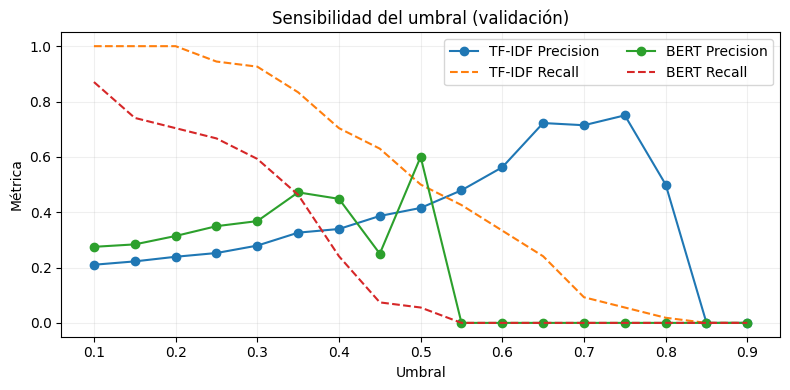

In [ ]:
fig,ax=plt.subplots(figsize=(8,4))
for name,p in [('TF-IDF',p_base_val),('BERT',p_bert_val)]:
    thresholds=np.linspace(.1,.9,17)
    ps=[precision_score(val.label,np.asarray(p)>=t,zero_division=0) for t in thresholds]
    rs=[recall_score(val.label,np.asarray(p)>=t,zero_division=0) for t in thresholds]
    ax.plot(thresholds,ps,marker='o',label=name+' Precision')
    ax.plot(thresholds,rs,linestyle='--',label=name+' Recall')
ax.set(title='Sensibilidad del umbral (validación)',xlabel='Umbral',ylabel='Métrica');ax.legend(ncol=2);ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUT/'sensibilidad_umbral.png',dpi=160);plt.show()

## 15. Exportación de entregables y conclusiones
Descarga las figuras, métricas CSV y particiones. **No redactar conclusiones numéricas antes de ejecutar.** En el informe explica: sesgo de selección KEV (solo vulnerabilidades ya explotadas), `Unknown` no es negativo verificado, posible desplazamiento temporal, variación por fabricante y coste de BERT vs línea base.

In [ ]:
import zipfile
zip_path=Path('CyberBERT_V1_Resultados.zip')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for f in OUT.glob('*'):
        if f.is_file():z.write(f,arcname=f.name)
print('Archivo generado:',zip_path,'tamaño:',round(zip_path.stat().st_size/1024,1),'KB')
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

Archivo generado: CyberBERT_V1_Resultados.zip tamaño: 606.6 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 16. Hallazgos, reflexión y defensa (completar con resultados)

1. **EDA:** informar número de registros, proporción Known/Unknown, proveedores dominantes y longitud de texto.
2. **Comparación:** completar F1 macro, Recall de Known y PR-AUC del baseline y BERT, citando `metricas_test.csv`.
3. **Costo:** comparar segundos de entrenamiento y facilidad de despliegue.
4. **Errores:** comentar al menos tres CVE fallidos e hipótesis verificables.
5. **Ética/validez:** `Unknown` no equivale a ausencia de ransomware. No usar este clasificador para decisiones de seguridad sin validación externa.
6. **Mejoras futuras:** validación temporal, limpieza de tokens explícitos, pruebas en otros proveedores, distilación y conjuntos de datos de etiquetado independiente.

**Diferenciación frente al notebook guía:** corpus CISA KEV, problema binario con etiqueta proxy, comparativa TF-IDF/BERT, umbral fijado por validación, PR-AUC, matrices y análisis de errores.